##**Will a customer subscribe to the bank's term deposit or not?**


# **Introduction and Dataset**

##Step 1 - Import Python libraries

In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


##Step 2 - Download Dataset
- url stores the download link.
- urlretrieve() downloads the dataset.
- ZipFile() opens the ZIP folder.
- extractall() extracts its contents into a folder called bank_data

In [136]:
import zipfile
import os
import urllib.request

# Download the dataset
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

urllib.request.urlretrieve(url, "bank_marketing.zip")

# Extract the ZIP file
with zipfile.ZipFile("bank_marketing.zip", "r") as zip_ref:
    zip_ref.extractall("bank_data")

print("Dataset downloaded and extracted!")

Dataset downloaded and extracted!


##Step 3 - Load Dataset

In [137]:
# Extract the original downloaded ZIP
with zipfile.ZipFile("bank_marketing.zip", "r") as zip_ref:
    zip_ref.extractall("bank_data")

# Search for any ZIP files inside the extracted folder
for root, folders, files in os.walk("bank_data"):
    for file in files:

        # Extract any ZIP files found
        if file.endswith(".zip"):
            zip_path = os.path.join(root, file)

            with zipfile.ZipFile(zip_path, "r") as zip_ref:
                zip_ref.extractall(root)

# Search for bank-full.csv
csv_path = None

for root, folders, files in os.walk("bank_data"):
    if "bank-full.csv" in files:
        csv_path = os.path.join(root, "bank-full.csv")
        break

# Load the dataset
if csv_path is not None:
    df = pd.read_csv(csv_path, sep=";")
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
else:
    print("File not found. Please show me the error.")

Dataset loaded successfully!
Dataset shape: (45211, 17)


In [138]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [139]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (45211, 17)


##Step 4 - Exploratory Data Analysis

In [140]:
# Display all column names
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [141]:
# Check for missing values
print(df.isnull().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [142]:
# Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [143]:
# Summary statistics
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


## 4.1 Looking at AND Visualising Target Variable Y

In [144]:
# Count the number of Yes and No outcomes
print(df["y"].value_counts())

# Calculate percentages
print(df["y"].value_counts(normalize=True) * 100)

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


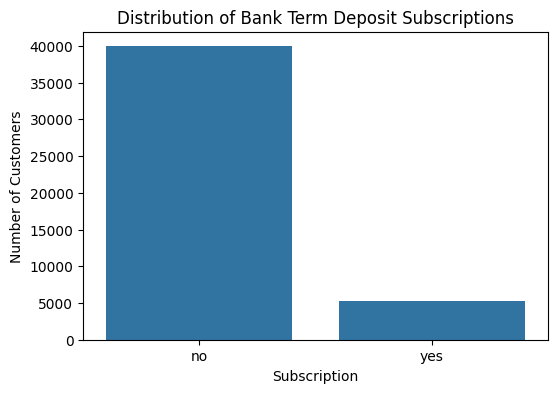

In [145]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="y")

plt.title("Distribution of Bank Term Deposit Subscriptions")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

## 4.2 Histograms to understand customer distribution

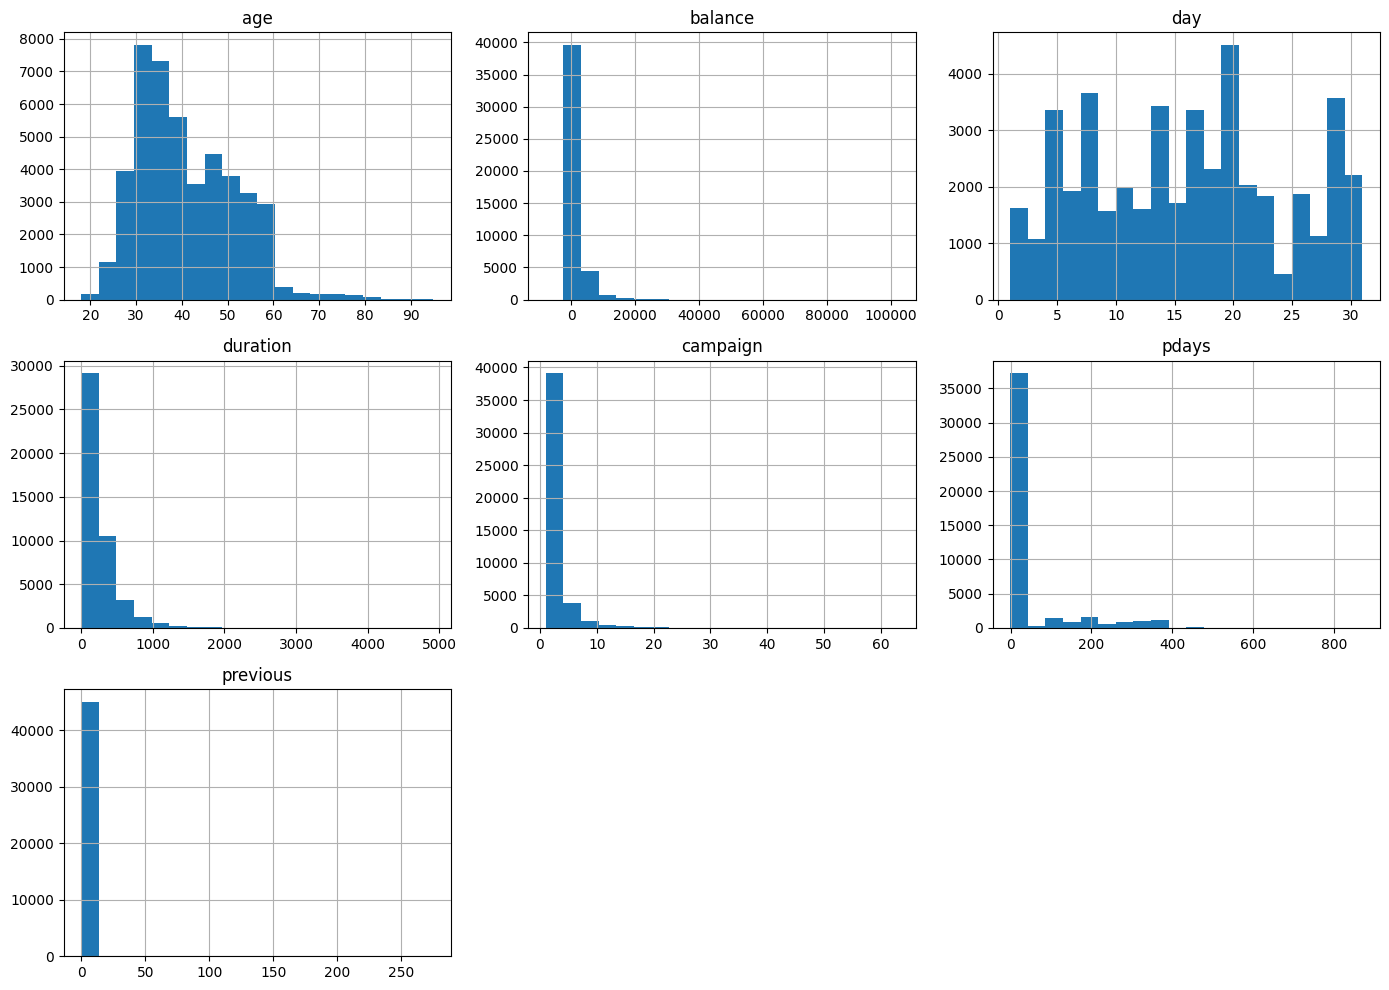

In [146]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

# Plot histograms
df[numerical_columns].hist(figsize=(14,10), bins=20)

plt.tight_layout()
plt.show()

## 4.3 Correlations and Heatmap

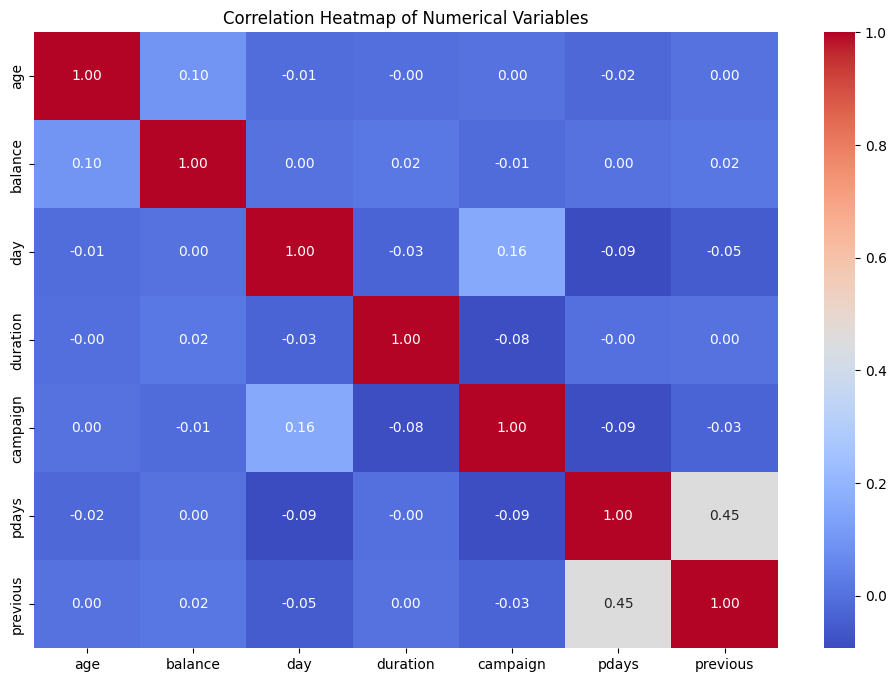

In [147]:
# Calculate correlations
correlation = df[numerical_columns].corr()

# Plot correlation heatmap
plt.figure(figsize=(12,8))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numerical Variables")

plt.show()

# **Data** **Preprocessing**

##Step 1 - Separating input variables and target variable
- Input variables (X): Information about the customers.


- Target variable (y): Whether they subscribed.

In [148]:
# Separate input variables and target variable

X = df.drop(columns=["y", "duration"])

y = df["y"].map({"no": 0, "yes": 1})

print("Input variables:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input variables:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  campaign  pdays  previous poutcome  
0  unknown    5   may         1     -1         0  unknown  
1  unknown    5   may         1     -1         0  unknown  
2  unknown    5   may         1     -1         0  unknown  
3  unknown    5   may         1     -1         0  unknown  
4  unknown    5   may         1     -1         0  unknown  

Target variable:
0    0
1    0
2    0
3    0
4    0
Name: y, dtype: int64


##Identify numercial and categorical variables

In [149]:
# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("\nCategorical columns:", categorical_columns)

Numerical columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [150]:
from sklearn.model_selection import train_test_split

# First split: 60% training, 40% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: divide remaining 40% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (27126, 15)
Validation set: (9042, 15)
Testing set: (9043, 15)


##Apply preprocessing, automate transformation

In [151]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns)
    ]
)

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (27126, 50)
Validation data shape: (9042, 50)
Testing data shape: (9043, 50)


#**Neural Network Model**

##Step 1 - Import Tensorflow

- A software library for the training and inference of neural networks

In [152]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


##Step 2 - Create the NN

In [153]:
# Build neural network
model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),

    layers.Dense(64, activation="relu"),

    layers.Dense(32, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,377 (21.00 KB)

 Trainable params: 5,377 (21.00 KB)

 Non-trainable params: 0 (0.00 B)

##Step 4 - Accounting for class imbalance
- Account for class imbalance
88.3% of customers did not subscribe, while only 11.7% did.

- We will use class weighting so that the model gives more importance to correctly learning the minority class.

In [154]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    0: weights[0],
    1: weights[1]
}

print("Class weights:", class_weights)

Class weights: {0: np.float64(0.5662338746712312), 1: np.float64(4.274503624330287)}


##Step 5 - Train the NN
- We train for upto 50 epochs, 1 epoch means the model has gone through the dataset once.

In [155]:
# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

# Track test loss across epochs for the assignment
class TestLossCallback(keras.callbacks.Callback):

    def __init__(self, test_data):
        super().__init__()
        self.test_data = test_data
        self.test_losses = []

    def on_epoch_end(self, epoch, logs=None):
        results = self.model.evaluate(
            self.test_data[0],
            self.test_data[1],
            verbose=0
        )

        self.test_losses.append(results[0])


test_loss_callback = TestLossCallback(
    (X_test_processed, y_test)
)

# Train model
history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping, test_loss_callback],
    verbose=1
)

Epoch 1/50
848/848 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7313 - loss: 0.5899 - val_accuracy: 0.7221 - val_loss: 0.5979
Epoch 2/50
848/848 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7693 - loss: 0.5593 - val_accuracy: 0.7471 - val_loss: 0.5736
Epoch 3/50
848/848 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7771 - loss: 0.5497 - val_accuracy: 0.7478 - val_loss: 0.5702
Epoch 4/50
848/848 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7810 - loss: 0.5425 - val_accuracy: 0.7529 - val_loss: 0.5664
Epoch 5/50
848/848 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7849 - loss: 0.5361 - val_accuracy: 0.7585 - val_loss: 0.5603
Epoch 6/50
848/848 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7864 - loss: 0.5302 - val_accuracy: 0.7631 - val_loss: 0.5546
Epoch 7/50
848/848 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7871 - loss: 0.5249 - val_accuracy: 0.7609 - val_loss: 0.5539
Epoch 8/50
848/848 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7903 - loss: 0.5199 - val_accuracy: 0.

##Step 6 - Plot training, validation and test losses across epochs

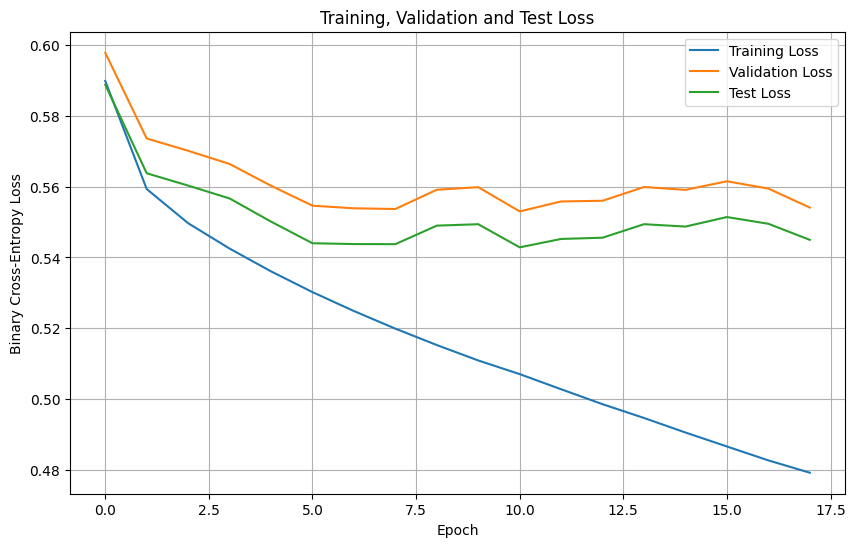

In [156]:
plt.figure(figsize=(10, 6))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.plot(test_loss_callback.test_losses, label="Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training, Validation and Test Loss")
plt.legend()
plt.grid(True)

plt.show()

# **Model Evaluation**

##How accurately can our neural network predict whether a customer subscribes?

##Step 1 - Calculating Accuracy

In [157]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Evaluate model on test dataset
test_loss, test_accuracy = model.evaluate(
    X_test_processed,
    y_test,
    verbose=0
)

# Generate predictions
y_probability = model.predict(
    X_test_processed,
    verbose=0
)

# Convert probabilities into 0 or 1
y_pred = (y_probability >= 0.5).astype(int).flatten()

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Test Loss:", test_loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

Test Loss: 0.5428699254989624
Test Accuracy: 0.7655645250469977
Test Accuracy (%): 76.55645250469976


Step 2 - Confusion Matrix

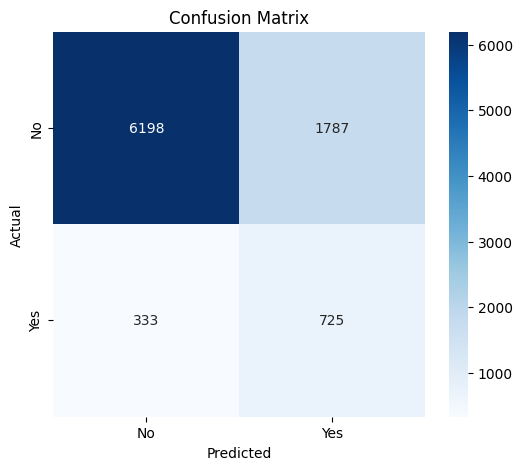

In [158]:
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [160]:
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[6198 1787]
 [ 333  725]]


##Step 3 - Calculate precision, recall and F1 score

In [159]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No", "Yes"]
))

              precision    recall  f1-score   support

          No       0.95      0.78      0.85      7985
         Yes       0.29      0.69      0.41      1058

    accuracy                           0.77      9043
   macro avg       0.62      0.73      0.63      9043
weighted avg       0.87      0.77      0.80      9043



# **Ablation Study: Hyperparameters**

Learning rate = 0.1

Learning rate = 0.01

Learning rate = 0.001

In [161]:
learning_rates = [0.1, 0.01, 0.001]

results = {}
lr_histories = {}

for lr in learning_rates:

    print("\nTraining with learning rate:", lr)

    # Build model
    experiment_model = keras.Sequential([
        layers.Input(shape=(X_train_processed.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    # Compile with different learning rate
    experiment_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Early stopping
    stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    # Train
    hist = experiment_model.fit(
        X_train_processed,
        y_train,
        validation_data=(X_val_processed, y_val),
        epochs=30,
        batch_size=32,
        class_weight=class_weights,
        callbacks=[stop],
        verbose=0
    )

    # Evaluate
    loss, accuracy = experiment_model.evaluate(
        X_test_processed,
        y_test,
        verbose=0
    )

    results[lr] = {
        "Test Loss": loss,
        "Test Accuracy": accuracy,
        "Epochs": len(hist.history["loss"])
    }

    lr_histories[lr] = hist.history

    print("Test loss:", loss)
    print("Test accuracy:", accuracy)


Training with learning rate: 0.1
Test loss: 0.8026698231697083
Test accuracy: 0.11699657142162323

Training with learning rate: 0.01
Test loss: 0.5079808831214905
Test accuracy: 0.81001877784729

Training with learning rate: 0.001
Test loss: 0.530837893486023
Test accuracy: 0.7716465592384338


##Step 2 - compare results

       Test Loss  Test Accuracy  Epochs
0.100   0.802670       0.116997     6.0
0.010   0.507981       0.810019    16.0
0.001   0.530838       0.771647    17.0


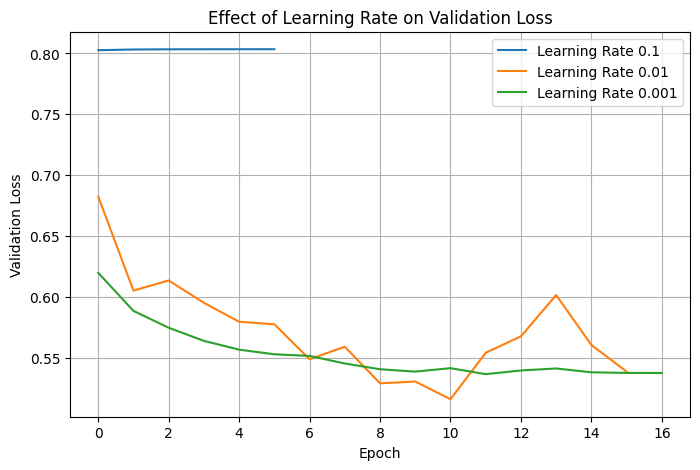

In [162]:
# Display comparison table
results_df = pd.DataFrame(results).T

print(results_df)

plt.figure(figsize=(8,5))

for lr in learning_rates:
    plt.plot(
        lr_histories[lr]["val_loss"],
        label=f"Learning Rate {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Effect of Learning Rate on Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# **Case Study: Successes and Failures**

In [163]:
# Find correctly and incorrectly predicted examples
correct = np.where(y_pred == np.array(y_test))[0]
incorrect = np.where(y_pred != np.array(y_test))[0]

print("Correct predictions:")
print(df.iloc[X_test.index[correct]][["age", "job", "balance", "y"]].head())

print("\nIncorrect predictions:")
print(df.iloc[X_test.index[incorrect]][["age", "job", "balance", "y"]].head())

Correct predictions:
       age         job  balance   y
25707   30      admin.     2284  no
16656   56  technician        0  no
30815   37  unemployed      924  no
26458   33  technician     1434  no
24712   54     retired     1826  no

Incorrect predictions:
       age         job  balance    y
43635   72     retired     2304  yes
36087   41      admin.     -109  yes
45198   37  management     1428   no
33203   35  management     1422   no
41916   53  management     3370   no
